# Midterm : le choc des prix de l'électricité de 2023 a-t-il accéléré le solaire sur les toits ?

Ce notebook part des fichiers publics bruts du dossier `data/` et arrive à tous les chiffres et graphiques de la présentation. On le lit de haut en bas : chaque section suit une étape de la consigne du cours, et chaque case fait une seule chose.

**Les trois variables**
- **Y (ce qu'on explique)** : le nombre de nouvelles installations solaires par commune et par année.
- **X (la cause qu'on teste)** : la hausse du tarif d'électricité des ménages en 2023 (tarif 2023 moins tarif 2022), en centimes par kWh.
- **Z (pour qui l'effet est plus fort ?)** : la part des logements habités par leur propriétaire. Un locataire ne peut en général pas poser de panneaux lui-même.

| Section | Ce qu'on fait | Slides |
|---|---|---|
| 0 | Préparer les outils | |
| 1 | Construire X, Y et Z à partir des fichiers bruts | 5, 6 |
| 2 | L'échantillon et le tableau de statistiques | 6, 7 |
| 3 | Chaque variable seule (dans le temps, dans l'espace) | 8 à 11 |
| 4 | X et Y ensemble, puis Z | 12 à 14 |
| 5 | Les problèmes de causalité | 15, 16 |
| 6 | Prochaines étapes pour le final (brouillons) | |

Pour tout relancer : *Kernel → Restart & Run All* (environ une minute).

## 0. Préparer les outils

On charge les bibliothèques dont on a besoin :
- `pandas` pour les tableaux,
- `numpy` pour les calculs,
- `matplotlib` pour les graphiques,
- `statsmodels` uniquement pour les intervalles de confiance de la section 4,
- `shapely` pour savoir dans quelle commune tombe chaque installation solaire (géométrie).

In [1]:
import json, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from shapely import STRtree, points, get_parts
from shapely.geometry import shape
from shapely.ops import unary_union

# trois couleurs qu'on réutilise partout, et un style de graphique plus léger
BLEU, ORANGE, VERT, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#9aa5b1"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e5e8eb"})

## 1. Construire les ingrédients à partir des fichiers bruts (slides 5 et 6)

### 1a. Un seul numéro par commune
Les communes suisses fusionnent presque chaque année, et chaque fichier utilise les numéros de communes de sa propre année. Si on ne fait rien, une même commune apparaît sous plusieurs numéros et on ne peut pas croiser les fichiers.

L'OFS publie la liste de toutes les fusions depuis 2010 (ancien numéro → nouveau numéro). On suit ces liens jusqu'à la commune qui existe en 2026. Exemple : A fusionne dans B en 2015, puis B dans C en 2021, donc A devient C.

In [2]:
fusions = pd.read_csv("data/bfs_commune_mutations.csv")
fusions = fusions[fusions.InitialCode != fusions.TerminalCode]     # on garde seulement les vrais changements de numéro
successeur = dict(zip(fusions.InitialCode, fusions.TerminalCode))

def to_2026(code):
    # on suit la chaîne de fusions jusqu'au bout
    while code in successeur:
        code = successeur[code]
    return code

print("exemple : la commune 343 est devenue", to_2026(343))

exemple : la commune 343 est devenue 329


### 1b. Population et canton de chaque commune
Le fichier de l'OFS mélange des lignes de cantons (`- Zürich`), de districts et de communes (`......0001 Aeugst am Albis`). On lit ligne par ligne : quand on voit un canton, on le retient ; quand on voit une commune, on la range avec ce canton.

In [3]:
brut = pd.read_csv("data/bfs_population.csv", encoding="latin1")
brut.columns = ["year", "place", "type", "nationality", "sex", "pop"]

lignes, canton = [], None
for lieu, annee, n in zip(brut.place, brut.year, brut["pop"]):
    if lieu.startswith("- "):                       # ligne de canton
        canton = lieu[2:]
    elif lieu.startswith("......"):                 # ligne de commune : le numéro est dans les caractères 6 à 9
        lignes.append((to_2026(int(lieu[6:10])), canton, annee, n))

pop = pd.DataFrame(lignes, columns=["bfs", "canton", "year", "pop"])
canton_of = pop.groupby("bfs").canton.last()                      # le canton de chaque commune
pop = pop.groupby(["bfs", "year"])["pop"].sum().unstack()          # communes fusionnées additionnées, une colonne par année
print("communes en 2026 :", len(pop))

communes en 2026 : 2110


### 1c. X : la hausse du tarif en 2023 (ElCom)
L'ElCom (le régulateur fédéral) publie le tarif de chaque gestionnaire de réseau, dans chaque commune, chaque année, pour plusieurs profils de consommation.

On garde le profil **H4** : le « ménage type » de l'ElCom (un 5 pièces qui consomme 4 500 kWh par an). Comme tout le monde est comparé sur le même ménage, les tarifs sont comparables d'une commune à l'autre.

In [4]:
elcom = pd.read_csv("data/elcom_tariffs_H2_H4_H7.csv")
h4 = elcom[elcom.category == "H4"].copy()
h4["bfs"] = h4.municipality.map(to_2026)
h4.head(3)

,period,municipality,operator,category,total,energy,grid,charge,aidfee,fixcosts,bfs
7981,2018,4726,131,H4,23.305,6.313,14.691,0.0,2.3,180.0,4726
7982,2018,177,591,H4,15.649,4.568,8.781,0.0,2.3,96.0,177
7983,2018,762,274,H4,21.098,7.092,11.706,0.0,2.3,120.0,762


Une commune peut être desservie par plusieurs gestionnaires (environ 6 % des communes). On fait la **moyenne** de leurs tarifs : l'ElCom ne dit pas combien de clients chacun a dans la commune, donc on ne peut pas pondérer.

On garde aussi la **part « énergie »** du prix, pour savoir plus tard d'où vient la hausse.

In [5]:
tarif = h4.groupby(["bfs", "period"]).total.mean().unstack()       # tarif total, ct/kWh, une colonne par année
energie = h4.groupby(["bfs", "period"]).energy.mean().unstack()     # la partie énergie du tarif
tarif[[2021, 2022, 2023]].head(3)

period,2021,2022,2023
bfs,,,
1,17.122,17.084,21.878
2,17.122,17.084,21.878
3,17.122,17.084,21.878


Pour certaines étapes il nous faut **un seul** gestionnaire par commune (les intervalles de confiance, les tarifs de reprise de la section 5). On prend le **gestionnaire principal** : celui qui apparaît le plus souvent pour la commune en 2023. Pour une commune issue de fusions, c'est celui qui desservait le plus d'anciennes communes.

In [6]:
gestionnaire_principal = h4[h4.period == 2023].groupby("bfs").operator.agg(lambda s: s.mode().iloc[0])
print("gestionnaires principaux, toutes communes confondues :", gestionnaire_principal.nunique(), "(495 une fois l'échantillon choisi, case 1g)")

gestionnaires principaux, toutes communes confondues : 500 (495 une fois l'échantillon choisi, case 1g)


### 1d. Z : la part de propriétaires (recensement 2000)
Le recensement 2000 donne, pour chaque commune, les logements selon le type d'occupant. Propriétaires = propriétaires d'appartement (PPE) + propriétaires seuls de la maison + copropriétaires.

**Z = logements occupés par leur propriétaire ÷ tous les logements occupés.**

Limite : les communes fusionnées avant 2010 ne peuvent pas être retrouvées (la liste des fusions commence en 2010), donc Z manque pour elles.

In [7]:
recensement = pd.read_csv("data/bfs_dwellings_by_occupant_2000_all.csv")
recensement = recensement[recensement.Gemeinde.str.match(r"^\d{4} ")].copy()     # lignes de communes : "0001 Aeugst am Albis"
recensement["bfs"] = recensement.Gemeinde.str[:4].astype(int).map(to_2026)
occupants = [c for c in recensement.columns if c not in ("Gemeinde", "Anzahl Zimmer", "bfs")]
recensement = recensement.groupby("bfs")[occupants].sum()                          # on additionne les tailles de logement et les fusions

proprietaires = recensement[["Stockwerk-/Wohnungseigentümer/in", "Alleineigentümer/in des Hauses", "Miteigentümer/in des Hauses"]].sum(axis=1)
part_proprietaires = proprietaires / recensement.sum(axis=1)
part_proprietaires.describe().round(2)

count    2397.00
mean        0.55
std         0.14
min         0.04
25%         0.47
50%         0.57
75%         0.65
max         0.96
dtype: float64

### 1e. Y : les installations solaires (registre de l'OFEN)
Le registre fédéral liste toutes les installations de production d'électricité en Suisse : type, puissance, date de mise en service, coordonnées. On garde le **photovoltaïque** et l'**année de mise en service**.

Attention : la date est celle du raccordement au réseau, quelques mois après la décision d'achat.

In [8]:
with zipfile.ZipFile("data/bfe_plants.csv.zip") as z:
    installations = pd.read_csv(z.open("ElectricityProductionPlant.csv"), encoding="utf-8-sig", dtype={"PostCode": str})

pv = installations[installations.SubCategory == "subcat_2"].copy()           # subcat_2 = photovoltaïque
pv["year"] = pd.to_datetime(pv.BeginningOfOperation, errors="coerce").dt.year
pv["kw"] = pv.InitialPower
print(f"installations solaires dans le registre : {len(pv):,}")

installations solaires dans le registre : 337,455


Il faut ensuite savoir **dans quelle commune** est chaque installation. On charge d'abord la forme (le polygone) de chaque commune, en regroupant les morceaux des communes fusionnées.

In [9]:
with open("data/swiss_boundaries_2020.geojson", encoding="utf-8") as f:
    formes = [ft for ft in json.load(f)["features"] if ft["properties"].get("OBJEKTART") == "Gemeindegebiet"]

polygones = pd.DataFrame({"bfs": [to_2026(int(ft["properties"]["BFS_NUMMER"])) for ft in formes],
                          "geom": [shape(ft["geometry"]) for ft in formes]})
polygones = polygones.groupby("bfs").geom.apply(lambda g: unary_union(list(g)))   # une forme par commune 2026
print("communes avec une forme :", len(polygones))

communes avec une forme : 2123


**Étape 1 : par les coordonnées.** Le registre donne des coordonnées suisses (LV95). On les convertit en longitude/latitude avec la formule approchée de swisstopo, puis on regarde quel polygone contient le point. `STRtree` est un index spatial : il évite de tester chaque point contre chacune des 2 000 communes.

In [10]:
E, N = (pv._x - 2600000) / 1e6, (pv._y - 1200000) / 1e6
lon = (2.6779094 + 4.728982 * E + 0.791484 * E * N + 0.1306 * E * N**2 - 0.0436 * E**3) * 100 / 36
lat = (16.9023892 + 3.238272 * N - 0.270978 * E**2 - 0.002528 * N**2 - 0.0447 * E**2 * N - 0.0140 * N**3) * 100 / 36

num_installation, num_commune = STRtree(polygones.values).query(points(lon, lat), predicate="within")
pv["bfs"] = pd.Series(polygones.index[num_commune], index=pv.index[num_installation])   # sans coordonnées : reste vide
print(f"placées grâce aux coordonnées : {pv.bfs.notna().mean():.1%}")

placées grâce aux coordonnées : 99.3%


**Étape 2 : par le code postal**, pour les rares installations sans coordonnées. L'annuaire des localités de swisstopo dit quelles communes couvre chaque code postal, avec la part des adresses. On prend la commune qui a le plus d'adresses.

In [11]:
with zipfile.ZipFile("data/ortschaftenverzeichnis_plz.csv.zip") as z:
    npa = pd.read_csv(z.open("AMTOVZ_CSV_LV95/AMTOVZ_CSV_LV95.csv"), sep=";", encoding="utf-8-sig", dtype={"PLZ4": str})
npa["part"] = npa.Adressenanteil.str.replace("%", "").astype(float)
commune_du_npa = npa.sort_values("part").drop_duplicates("PLZ4", keep="last").set_index("PLZ4")["BFS-Nr"]

pv["bfs"] = pv.bfs.fillna(pv.PostCode.map(commune_du_npa).map(to_2026, na_action="ignore"))
print(f"placées au total : {pv.bfs.notna().mean():.1%}")

placées au total : 100.0%


### 1f. Une variable de contrôle : les maisons individuelles (statistique des bâtiments 2021)
On ne s'en sert que pour discuter Z : la part de bâtiments d'habitation qui sont des maisons individuelles.

In [12]:
batiments = pd.read_csv("data/bfs_gws_buildings_2015_2024.csv")
batiments = batiments[(batiments.TIME_PERIOD == 2021) & batiments.GEMEINDENAME.astype(str).str.fullmatch(r"\d+")].copy()
batiments["bfs"] = batiments.GEMEINDENAME.astype(int).map(to_2026)
batiments = batiments.groupby(["bfs", batiments.GKATS.astype(str)]).OBS_VALUE.sum().unstack()
part_maisons = batiments["1021"] / batiments["_T"]          # 1021 = maison individuelle, _T = tous les bâtiments

### 1g. L'échantillon
On garde les communes qui ont une population **et** un tarif 2022 **et** un tarif 2023 (sans tarif 2022, on ne peut pas calculer la hausse). Années 2015 à 2025 : 2026 est incomplète, l'extrait du registre date de septembre 2026.

In [13]:
echantillon = sorted(set(pop.index) & set(tarif.index[tarif[2022].notna() & tarif[2023].notna()]))
exclues = sorted(set(pop.index) - set(echantillon))
print(f"échantillon : {len(echantillon):,} communes sur {len(pop):,}")
print("communes exclues (pas de tarif 2022), par canton :", canton_of[exclues].value_counts().to_dict())

échantillon : 2,098 communes sur 2,110
communes exclues (pas de tarif 2022), par canton : {'Graubünden / Grigioni / Grischun': 8, 'Aargau': 2, 'Fribourg / Freiburg': 1, 'Vaud': 1}


On construit le tableau **`communes`** : une ligne par commune, avec X, Z et quelques contrôles.

In [14]:
communes = pd.DataFrame(index=pd.Index(echantillon, name="bfs"))
communes["canton"] = canton_of
communes["operator"] = gestionnaire_principal
communes["regional_utility"] = communes.operator.map(communes.operator.value_counts()) >= 10   # gestionnaire principal de 10+ communes
communes["pop_2021"] = pop[2021]
communes["shock23"] = tarif[2023] - tarif[2022]                     # X : la hausse 2023
communes["shock_energy23"] = energie[2023] - energie[2022]          # la part énergie de cette hausse
communes["t2022"] = tarif[2022]
communes["owner_share_2000"] = part_proprietaires                   # Z
communes["sfh_share_2021"] = part_maisons
communes["pv_stock21_pc"] = pv[pv.year <= 2021].groupby("bfs").size().reindex(echantillon, fill_value=0) / communes.pop_2021 * 1000
tarif = tarif.loc[echantillon, 2015:2027]
communes.head(3)

,canton,operator,regional_utility,pop_2021,shock23,shock_energy23,t2022,owner_share_2000,sfh_share_2021,pv_stock21_pc
bfs,,,,,,,,,,
1,Zürich,486,True,1988,4.794,4.156,17.084,0.595238,0.694097,27.665996
2,Zürich,486,True,12404,4.794,4.156,17.084,0.288955,0.544643,10.561109
3,Zürich,486,True,5632,4.794,4.156,17.084,0.468602,0.715184,11.896307


Et le tableau **`installs`** : une ligne par commune et par année, avec le nombre de nouvelles installations (Y). Une commune sans installation une année reçoit 0, pas une case vide.

In [15]:
placees = pv[pv.bfs.isin(echantillon) & pv.year.between(2015, 2025)]
grille = pd.MultiIndex.from_product([echantillon, range(2015, 2026)], names=["bfs", "year"])
installs = (placees.groupby(["bfs", "year"]).agg(n_new=("kw", "size"), kw_new=("kw", "sum"))
            .reindex(grille, fill_value=0).reset_index())

print(f"installations 2015-2025 dans l'échantillon : {installs.n_new.sum():,} ; plus de 30 kW : {(placees.kw > 30).mean():.0%}")
print(f"{len(installs):,} lignes commune-année ; {communes.operator.nunique()} gestionnaires principaux ; communes sans Z : {communes.owner_share_2000.isna().sum()}")

installations 2015-2025 dans l'échantillon : 297,633 ; plus de 30 kW : 12%
23,078 lignes commune-année ; 495 gestionnaires principaux ; communes sans Z : 35


## 2. L'échantillon et le tableau de statistiques (slides 6 et 7)

On résume Y **par commune** : la moyenne d'installations par an **avant** le choc (2017-2021) et **après** (2023-2024).

Pourquoi on saute 2022 : les tarifs 2023 ont été publiés en août 2022, donc 2022 est à moitié « avant », à moitié « après ». Le garder brouillerait la comparaison.

**La croissance** (le Y qu'on utilise en section 4) = log(1 + installations par an 2023-24) − log(1 + installations par an 2017-21).
- Le **log** mesure une croissance **relative**. Un village qui passe de 2 à 6 (×3) et une ville qui passe de 200 à 260 (×1,3) deviennent comparables : 0,85 contre 0,26.
- Le **1 +** sert aux communes à zéro installation : log(0) n'existe pas, log(1) = 0.

In [16]:
communes["n_pre"] = installs[installs.year.between(2017, 2021)].groupby("bfs").n_new.mean()
communes["n_post"] = installs[installs.year.isin([2023, 2024])].groupby("bfs").n_new.mean()
communes["growth"] = np.log1p(communes.n_post) - np.log1p(communes.n_pre)

resume = communes[["n_pre", "n_post", "growth", "shock23", "owner_share_2000"]].describe().T
resume[["count", "mean", "std", "min", "50%", "max"]].round(2)          # le tableau de la slide 7

,count,mean,std,min,50%,max
n_pre,2098.0,7.97,9.77,0.00,5.20,112.80
n_post,2098.0,28.44,33.54,0.00,18.50,484.00
growth,2098.0,1.10,0.44,-0.82,1.13,2.41
shock23,2098.0,6.58,5.01,-0.47,5.06,43.00
owner_share_2000,2063.0,0.54,0.15,0.04,0.56,0.96


Comment lire le tableau : `count` = nombre de communes, `mean` = moyenne, `std` = écart type (la dispersion), `50%` = médiane.

Pour Y, la moyenne (28,4) est bien plus haute que la médiane (18,5) : quelques grandes villes tirent la moyenne vers le haut. C'est ce qu'on appelle une variable **asymétrique**, et c'est pour ça qu'on regarde souvent la médiane.

## 3. Chaque variable seule (slides 8 à 11)

Pour chaque variable, la consigne demande : sa nature (comptage, continue, part…), les transformations, les valeurs extrêmes, et son comportement **dans le temps** et **dans l'espace**.

### 3a. Y dans le temps (slide 8)

installations 2021 -> 2023 : 23,291 -> 61,682 (+165%)


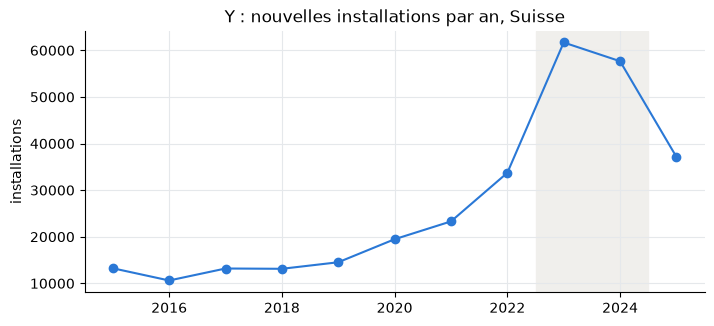

In [17]:
par_an = installs.groupby("year").n_new.sum()
print(f"installations 2021 -> 2023 : {par_an[2021]:,} -> {par_an[2023]:,} ({par_an[2023] / par_an[2021] - 1:+.0%})")

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(par_an.index, par_an, marker="o", color=BLEU)
ax.axvspan(2022.5, 2024.5, color="#f0efec", zorder=0)              # zone grisée : 2023-24, après le choc
ax.set(title="Y : nouvelles installations par an, Suisse", ylabel="installations")
plt.show()

### 3b. Y entre communes (slide 9)
Un histogramme montre la forme de la distribution. La dernière barre regroupe toutes les communes à 100 ou plus (on les « plafonne » à 100 pour que le graphique reste lisible).

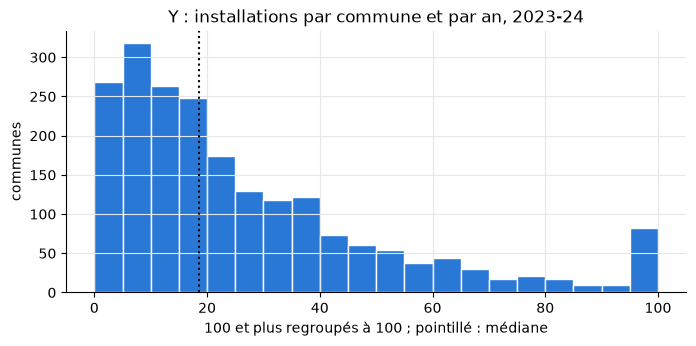

In [18]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(communes.n_post.clip(upper=100), bins=range(0, 105, 5), color=BLEU, edgecolor="white")
ax.axvline(communes.n_post.median(), color="black", ls=":")
ax.set(title="Y : installations par commune et par an, 2023-24", xlabel="100 et plus regroupés à 100 ; pointillé : médiane", ylabel="communes")
plt.show()

### 3c. Z (slide 10)
Z est une **part** (entre 0 et 1). Elle ne bouge pas dans le temps chez nous : un seul recensement, en 2000.

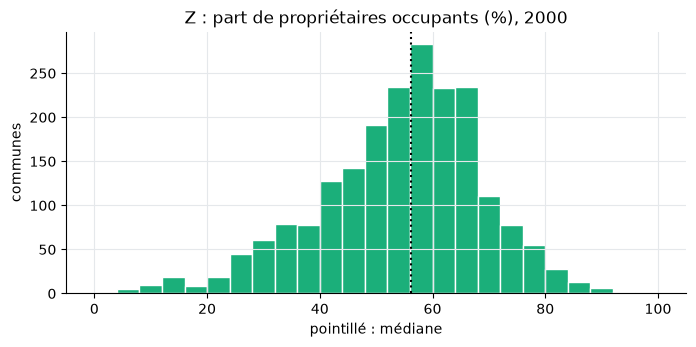

In [19]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(communes.owner_share_2000 * 100, bins=range(0, 101, 4), color=VERT, edgecolor="white")
ax.axvline(communes.owner_share_2000.median() * 100, color="black", ls=":")
ax.set(title="Z : part de propriétaires occupants (%), 2000", xlabel="pointillé : médiane", ylabel="communes")
plt.show()

### 3d. Les cartes (slides 9, 10 et 11)
Une seule fonction pour les trois cartes. Elle colorie chaque commune selon la classe de sa valeur (gris = pas de donnée). On simplifie un peu les frontières pour que ça dessine plus vite.

In [20]:
def dessiner_carte(valeurs, limites, etiquettes, titre):
    couleurs = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#104281"][-len(etiquettes):]
    fig, ax = plt.subplots(figsize=(10, 6))
    for bfs, geom in polygones.items():
        v = valeurs.get(bfs)
        couleur = "#e6e6e6" if pd.isna(v) else couleurs[np.digitize(v, limites)]   # np.digitize : dans quelle classe tombe v
        for morceau in get_parts(geom.simplify(0.001)):
            ax.fill(*morceau.exterior.xy, color=couleur, linewidth=0)
    ax.set_aspect(1.46); ax.axis("off")                       # 1,46 = 1 / cos(latitude de la Suisse), pour ne pas écraser la carte
    ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in couleurs + ["#e6e6e6"]], etiquettes + ["pas de donnée"],
              title=titre, ncol=len(etiquettes) + 1, loc="upper left", bbox_to_anchor=(0, 0.02))
    plt.show()

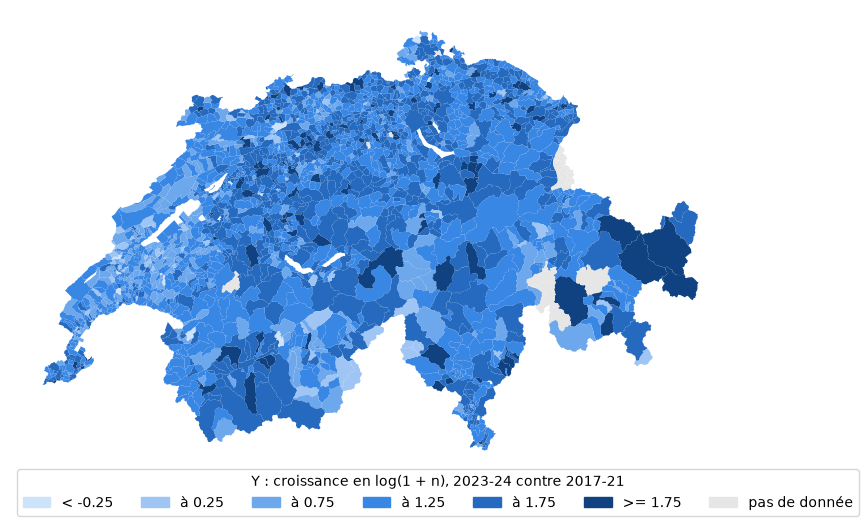

communes avec une croissance positive : 98%


In [21]:
dessiner_carte(communes.growth, [-0.25, 0.25, 0.75, 1.25, 1.75], ["< -0.25", "à 0.25", "à 0.75", "à 1.25", "à 1.75", ">= 1.75"],
               "Y : croissance en log(1 + n), 2023-24 contre 2017-21")
print(f"communes avec une croissance positive : {(communes.growth > 0).mean():.0%}")

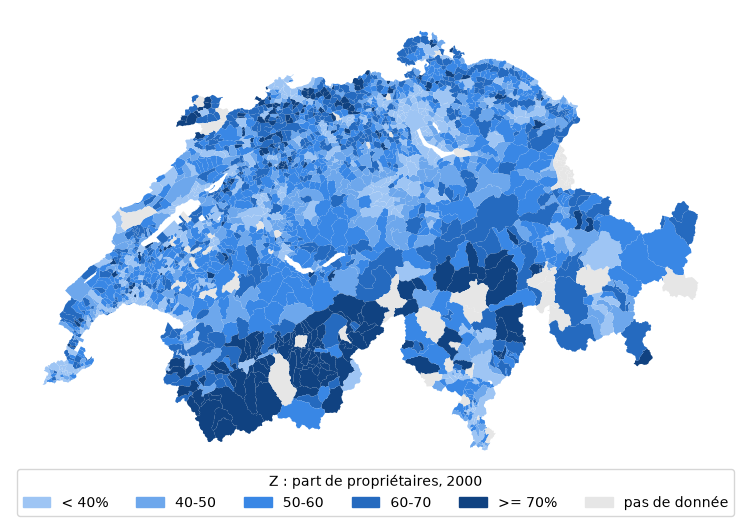

In [22]:
dessiner_carte(communes.owner_share_2000, [0.4, 0.5, 0.6, 0.7], ["< 40%", "40-50", "50-60", "60-70", ">= 70%"], "Z : part de propriétaires, 2000")

### 3e. X, la hausse du tarif (slides 2 et 11)
X est **continue** (en ct/kWh). On la garde telle quelle, sans log :
- elle n'est pas très asymétrique,
- quelques communes ont même une petite baisse, et on ne peut pas prendre le log d'un nombre négatif.

Les 17 communes au-dessus de 25 ct sont de vraies petites entreprises locales, pas des erreurs : on les **garde**. Supprimer des données vraies fausserait le résultat.

In [23]:
print(communes.shock23.describe().round(2))
print("communes au-dessus de 25 ct :", (communes.shock23 > 25).sum())
print(f"hausse médiane par rapport au tarif 2022 : {(communes.shock23 / communes.t2022).median():+.0%}")      # slide 2

count    2098.00
mean        6.58
std         5.01
min        -0.47
25%         3.80
50%         5.06
75%         9.85
max        43.00
Name: shock23, dtype: float64
communes au-dessus de 25 ct : 17
hausse médiane par rapport au tarif 2022 : +28%


Deux chiffres clés :
- **La part énergie** : quelle part de la hausse vient du prix de l'électricité elle-même (et pas des frais de réseau).
- **La part « à l'intérieur des cantons »** : on enlève à chaque commune la moyenne de son canton, et on regarde quelle part de la dispersion reste. Si elle est grande, des communes du même canton ont eu des hausses très différentes, et on peut les comparer entre elles.

In [24]:
print(f"part énergie de la hausse moyenne : {communes.shock_energy23.mean() / communes.shock23.mean():.0%}")
dans_canton = communes.shock23 - communes.groupby("canton").shock23.transform("mean")     # on enlève la moyenne du canton
print(f"part de la variance à l'intérieur des cantons : {dans_canton.var() / communes.shock23.var():.0%}")

part énergie de la hausse moyenne : 87%
part de la variance à l'intérieur des cantons : 74%


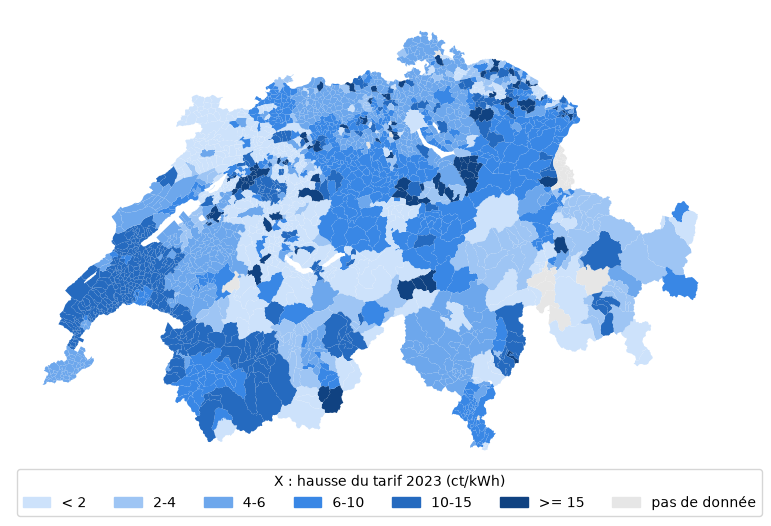

In [25]:
dessiner_carte(communes.shock23, [2, 4, 6, 10, 15], ["< 2", "2-4", "4-6", "6-10", "10-15", ">= 15"], "X : hausse du tarif 2023 (ct/kWh)")

Le graphique par canton : une ligne par canton. Le trait fin va du minimum au maximum (coupé à 25 ct), la barre épaisse couvre les 50 % du milieu, le point est la médiane.

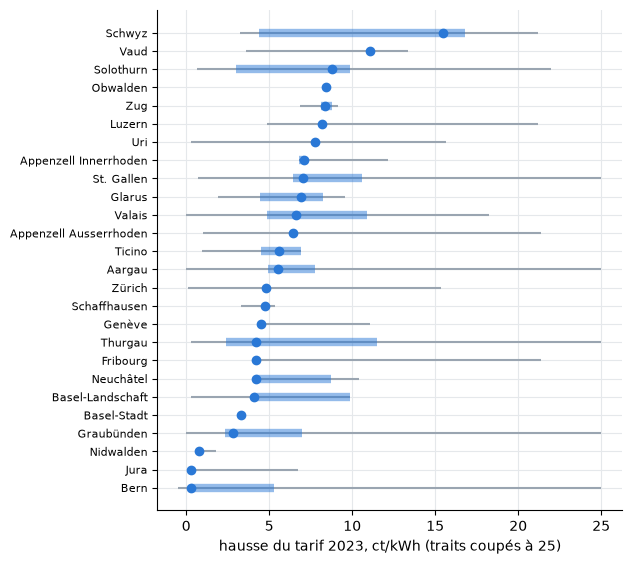

In [26]:
stats = communes.groupby("canton").shock23.describe().sort_values("50%")
lignes_graph = range(len(stats))
fig, ax = plt.subplots(figsize=(6, 6.5))
ax.hlines(lignes_graph, stats["min"], stats["max"].clip(upper=25), color=GRIS)
ax.hlines(lignes_graph, stats["25%"], stats["75%"], color=BLEU, lw=6, alpha=.5)
ax.plot(stats["50%"], lignes_graph, "o", color=BLEU)
ax.set_yticks(lignes_graph, [nom.split(" / ")[0] for nom in stats.index], fontsize=8)
ax.set_xlabel("hausse du tarif 2023, ct/kWh (traits coupés à 25)")
plt.show()

## 4. X et Y ensemble (slides 12 à 14)

### 4a. Les trois tiers (slide 12)
On trie les communes selon X et on les coupe en trois groupes de taille à peu près égale : choc **faible**, **moyen**, **fort**. Les communes qui ont exactement la même valeur restent ensemble, d'où des groupes un peu inégaux.

In [27]:
communes["third"] = pd.qcut(communes.shock23, 3, labels=["faible", "moyen", "fort"])
print("hausse moyenne par tiers :", communes.groupby("third", observed=True).shock23.mean().round(1).to_dict())
print("communes par tiers :", communes.third.value_counts().sort_index().to_dict())

hausse moyenne par tiers : {'faible': 2.0, 'moyen': 5.9, 'fort': 12.3}
communes par tiers : {'faible': 715, 'moyen': 721, 'fort': 662}


**L'indice (2021 = 100).** Les trois groupes n'ont pas la même taille, donc on ne peut pas comparer leurs totaux bruts. Pour chaque groupe, on additionne les installations de l'année et on divise par le total du même groupe en 2021, fois 100. Un indice de 290 veut dire « 2,9 fois plus qu'en 2021 ».

Limite : on **additionne** les installations, donc les grandes villes pèsent beaucoup. C'est pour ça que la case 4b compte chaque commune une fois.

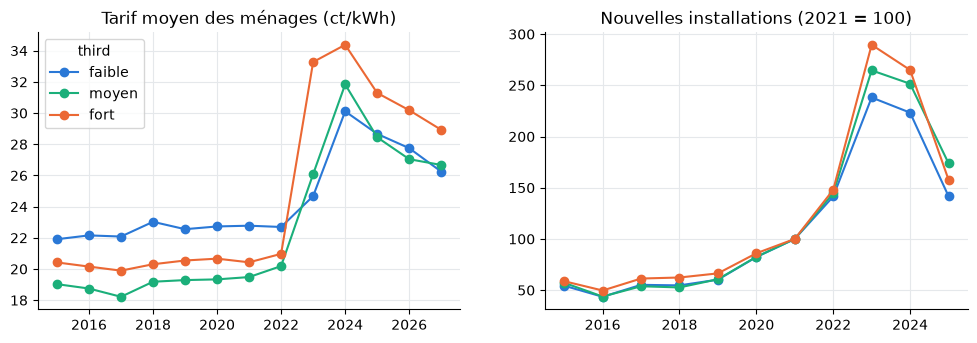

indice 2023 : {'faible': 238.0, 'moyen': 265.0, 'fort': 290.0}
écart de tarif fort - faible : 8.6 ct (2023) -> 4.3 ct (2024)
hausse du tarif 2023 -> 2024 : {'faible': 5.4, 'moyen': 5.8, 'fort': 1.1}


In [28]:
tarif_par_tiers = tarif.groupby(communes.third, observed=True).mean().T
totaux = installs.join(communes.third, on="bfs").groupby(["year", "third"], observed=True).n_new.sum().unstack()
indice = totaux / totaux.loc[2021] * 100

fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
tarif_par_tiers.plot(ax=axs[0], marker="o", color=[BLEU, VERT, ORANGE], title="Tarif moyen des ménages (ct/kWh)", xlabel="")
indice.plot(ax=axs[1], marker="o", color=[BLEU, VERT, ORANGE], title="Nouvelles installations (2021 = 100)", legend=False, xlabel="")
plt.show()

print("indice 2023 :", indice.loc[2023].round().to_dict())
ecart = tarif_par_tiers["fort"] - tarif_par_tiers["faible"]
print(f"écart de tarif fort - faible : {ecart[2023]:.1f} ct (2023) -> {ecart[2024]:.1f} ct (2024)")
print("hausse du tarif 2023 -> 2024 :", (tarif_par_tiers.loc[2024] - tarif_par_tiers.loc[2023]).round(1).to_dict())

Avant 2022 les lignes avancent ensemble ; en 2023 le tiers « fort » grandit le plus ; en 2024 les autres rattrapent une partie de la hausse (l'écart de tarif est divisé par deux).

### 4b. Commune par commune, à l'intérieur des cantons (slide 13)
Les cantons ont leurs propres subventions et règles de construction. Pour ne pas les confondre avec l'effet du tarif, on compare chaque commune **seulement aux communes de son canton** : on enlève la moyenne du canton à X et à la croissance, puis on trace une droite.

(C'est exactement ce que fait une régression avec des « effets fixes canton ».)

In [29]:
x = communes.shock23 - communes.groupby("canton").shock23.transform("mean")      # X moins la moyenne du canton
y = communes.growth - communes.groupby("canton").growth.transform("mean")         # croissance moins la moyenne du canton

pente = np.polyfit(x, y, 1)[0]                                                       # la pente de la droite
print(f"pente : {pente * 10:.2f} log points de croissance par +10 ct/kWh, à l'intérieur des cantons")
print(f"en pourcentage : environ {np.exp(pente * 10) - 1:+.0%}")

pente : 0.24 log points de croissance par +10 ct/kWh, à l'intérieur des cantons
en pourcentage : environ +27%


Le nuage compte 2 098 points, on ne voit pas grand-chose. On fait donc aussi 20 groupes de même taille selon x et on trace la moyenne de chaque groupe (un « nuage par classes »).

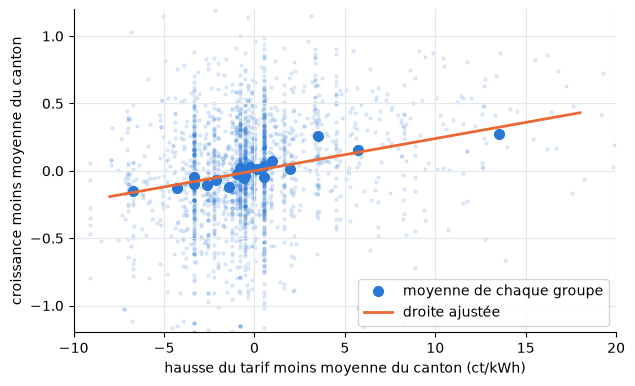

In [30]:
groupes = pd.qcut(x.rank(method="first"), 20, labels=False)        # 20 groupes égaux (rank départage les ex aequo)
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.scatter(x, y, s=5, alpha=.12, color=BLEU)
ax.plot(x.groupby(groupes).mean(), y.groupby(groupes).mean(), "o", color=BLEU, ms=7, label="moyenne de chaque groupe")
ax.plot([-8, 18], [-8 * pente, 18 * pente], color=ORANGE, lw=2, label="droite ajustée")
ax.set(xlim=(-10, 20), ylim=(-1.2, 1.2), xlabel="hausse du tarif moins moyenne du canton (ct/kWh)", ylabel="croissance moins moyenne du canton")
ax.legend(); plt.show()

### 4c. Intervalle de confiance et test placebo (slide 13)
**Intervalle de confiance à 95 %** : la fourchette de valeurs plausibles pour la vraie pente. Si 0 n'est pas dedans, le lien a très peu de chances d'être dû au hasard.

**Regroupement par gestionnaire (cluster)** : toutes les communes d'un même gestionnaire ont reçu le même choc, elles ne sont donc pas indépendantes. On le dit au modèle, sinon il serait trop sûr de lui. 495 gestionnaires, c'est plus proche de 495 expériences que de 2 098.

**Placebo** : on refait le même calcul sur une période **avant** le choc (croissance de 2017-18 à 2020-21). Si les communes à fort choc grandissaient déjà plus vite pour d'autres raisons, on trouverait une pente positive. On doit trouver zéro.

In [31]:
avant = installs[installs.year.isin([2020, 2021])].groupby("bfs").n_new.mean()
plus_tot = installs[installs.year.isin([2017, 2018])].groupby("bfs").n_new.mean()
placebo = np.log1p(avant) - np.log1p(plus_tot)
y_placebo = placebo - placebo.groupby(communes.canton).transform("mean")

for nom, resultat in [("après le choc (2023-24)", y), ("avant le choc (placebo, 2020-21)", y_placebo)]:
    ajustement = sm.OLS(resultat, sm.add_constant(x / 10)).fit(cov_type="cluster", cov_kwds={"groups": communes.operator})
    bas, haut = ajustement.conf_int().loc["shock23"]
    print(f"{nom} : pente {ajustement.params['shock23']:.2f}, IC 95% {bas:.2f} à {haut:.2f}")

après le choc (2023-24) : pente 0.24, IC 95% 0.20 à 0.28
avant le choc (placebo, 2020-21) : pente 0.02, IC 95% -0.03 à 0.07


### 4d. Ajouter Z (slide 14)
Les mêmes tiers, mais séparément pour les communes en dessous et au-dessus de la médiane de propriétaires (56 %). C'est **descriptif** : Z bouge aussi avec la taille de la commune et le type de logement (case suivante).

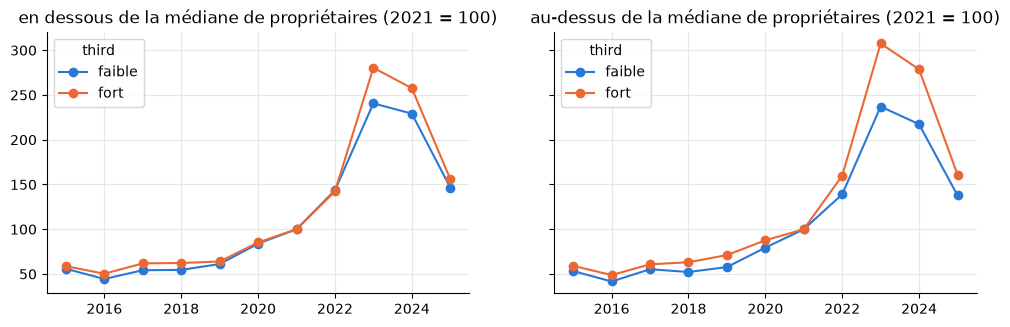

third            faible   fort
year z_group                  
2022 au-dessus    139.0  160.0
     en dessous   144.0  142.0
2023 au-dessus    237.0  308.0
     en dessous   241.0  280.0

In [32]:
mediane = communes.owner_share_2000.median()
communes["z_group"] = pd.cut(communes.owner_share_2000, [0, mediane, 1], right=False, labels=["en dessous", "au-dessus"])
totaux_z = installs.join(communes[["third", "z_group"]], on="bfs").groupby(["year", "z_group", "third"], observed=True).n_new.sum()
indice_z = (totaux_z / totaux_z.xs(2021, level="year") * 100).unstack(["z_group", "third"])

fig, axs = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, groupe in zip(axs, ["en dessous", "au-dessus"]):
    indice_z[groupe][["faible", "fort"]].plot(ax=ax, marker="o", color=[BLEU, ORANGE], title=f"{groupe} de la médiane de propriétaires (2021 = 100)", xlabel="")
plt.show()
indice_z.loc[[2022, 2023]].stack(0, future_stack=True)[["faible", "fort"]].round()      # 2022 et 2023, choc fort contre faible

### 4e. Qu'est-ce qui bouge avec X, Y et Z ? (corrélations)
Une corrélation r va de −1 à +1 : +1 = les deux montent ensemble parfaitement, 0 = pas de lien en ligne droite, −1 = l'un monte quand l'autre descend.

In [33]:
communes["log_pop"] = np.log(communes.pop_2021)
noms = {"shock23": "X : choc", "growth": "Y : croissance", "owner_share_2000": "Z : propriétaires", "t2022": "tarif 2022",
        "sfh_share_2021": "part de maisons individuelles", "pv_stock21_pc": "PV pour 1000 hab. 2021", "log_pop": "log population"}
communes[list(noms)].rename(columns=noms).corr()[["X : choc", "Y : croissance", "Z : propriétaires"]].round(2)

,X : choc,Y : croissance,Z : propriétaires
X : choc,1.00,0.14,-0.05
Y : croissance,0.14,1.00,-0.13
Z : propriétaires,-0.05,-0.13,1.00
tarif 2022,-0.26,-0.07,-0.00
part de maisons individuelles,0.05,0.08,0.41
PV pour 1000 hab. 2021,0.03,-0.47,0.40
log population,0.08,0.43,-0.62


## 5. Les problèmes de causalité (slides 15 et 16)

**Y a-t-il autre chose ?** Le choc n'est pas tiré au hasard : ce sont les gestionnaires qui ont fixé leurs tarifs. Les mêmes gestionnaires fixent aussi le **tarif de reprise** (ce qu'ils paient pour le courant solaire injecté dans le réseau).

Les tarifs de reprise viennent de la base pvtarif de VESE, sous licence, réservée à notre groupe. On compare 2021 et 2023 : en 2022, les gestionnaires qui suivaient le prix du marché trimestriel n'ont qu'une photo d'un trimestre.

*Données des tarifs de rétribution : VESE / pvtarif.ch (http://www.vese.ch, http://www.pvtarif.ch).*

In [34]:
# les grands gestionnaires (principaux dans 10 communes ou plus) ont-ils augmenté moins ?
print(communes.groupby("regional_utility").shock23.mean().round(1))

regional_utility
False    8.5
True     5.8
Name: shock23, dtype: float64


In [35]:
def tarif_reprise(annee):
    # une ligne par gestionnaire ; tarif de reprise = énergie + garantie d'origine
    with open(f"data/vese_pvtarif_{annee}.json", encoding="utf-8") as f:
        vese = pd.DataFrame.from_dict(json.load(f), orient="index")
    energie_v = pd.to_numeric(vese.energy1, errors="coerce")
    origine = pd.to_numeric(vese.eco1, errors="coerce").fillna(0).where(vese.ecoIncl != "y", 0)   # sauf si déjà incluse
    return (energie_v + origine).where(energie_v > 0).rename(int)                                   # 0 = case vide

hausse_reprise = communes.operator.map(tarif_reprise(2023)) - communes.operator.map(tarif_reprise(2021))
ok = hausse_reprise.notna()
print(f"X contre hausse du tarif de reprise 2021->2023 : r = {communes.shock23[ok].corr(hausse_reprise[ok]):.2f} ({ok.sum():,} communes)")

X contre hausse du tarif de reprise 2021->2023 : r = 0.79 (1,994 communes)


**Ce que ça veut dire**
- **Les gestionnaires ont choisi le choc** : les grands ont augmenté moins (5,8 contre 8,5 ct), et les communes avec un tarif 2022 élevé aussi (r = −0,26).
- **Le tarif de reprise a bougé avec X** (r = 0,79) : pour l'instant on ne peut pas séparer les deux prix.
- **Tout le monde a été « traité »** : toutes les communes ont vécu la crise, et les communes à faible choc ont en partie rattrapé en 2024. On mesure donc une différence de court terme entre communes.
- **Facteurs locaux non observés** : subventions communales, files d'attente des installateurs.

**Et l'inverse ?** Peu probable : les tarifs 2023 ont été publiés fin août 2022, avant les installations qu'on compte. Plus de solaire pourrait faire monter les frais de réseau, mais 87 % de la hausse vient de la partie énergie, et X n'a pas de lien avec le solaire déjà installé en 2021 (r = 0,03).

**Peut-on généraliser ?** Avec prudence : une seule crise très médiatisée ; des moyennes par commune, pas des ménages ; Y compte toutes les installations (12 % font plus de 30 kW : fermes, entreprises) ; 12 communes exclues et Z manquant pour 35.

## 6. Prochaines étapes pour le final (brouillons)

Le midterm est **descriptif**. Le final doit répondre à la question causale : est-ce que la hausse du tarif a *causé* plus d'installations ? Chaque étape ci-dessous répond à un problème précis de la section 5.

Une première version de presque toutes ces analyses existe déjà dans le dépôt (`src/s02` à `src/s08`, résultats dans `paper/PAPER.md`). Il faut la relire ensemble, la comprendre et la vérifier avant de la présenter comme la nôtre.

**Ce que demande le rapport final (80 % de la note, rendu sur Moodle le 18 décembre à 16 h)**
- Un article de 3 000 mots maximum, écrit dans un notebook, prêt pour Medium, pour des étudiants EPFL avec des bases en statistique.
- Il doit parler de : (1) contexte et question, (2) causalité et méthode, (3) sources de données et leurs biais, (4) résultats en images, (5) limites et extensions.
- Le notebook doit tourner du début à la fin sans modification, avec le code de chaque résultat, et charger les données par des liens URL (par exemple un dépôt GitHub).
- Pas de nettoyage ni d'exploration détaillée dans l'article : ce notebook-ci peut servir de notebook séparé (non noté). Les tableaux de régression vont en annexe (hors limite de mots).
- Notation : domaine et littérature 20 points, économétrie 40 points, communication 20 points.

**À régler en premier** : notre dépôt est privé et les données VESE ne peuvent pas être publiques. Il faudra un dépôt public avec seulement les données ouvertes, et une décision sur la partie tarif de reprise (demander à VESE, demander aux enseignants, ou la traiter comme une limite).

### Étape 1 : la même pente, année par année (étude d'événement, « event study »)
**Pourquoi** : le placebo de la section 4 ne teste qu'une période. Année par année, on voit si les communes à fort choc évoluaient comme les autres avant 2022 (tendances parallèles), si quelque chose se passe déjà en 2022 (anticipation), et si l'effet disparaît en 2025.

**Comment (brouillon ci-dessous)** : pour chaque année, croissance par rapport à 2021 = log(1 + n de l'année) − log(1 + n en 2021), on enlève la moyenne du canton, et on calcule la pente sur X. Différencier par rapport à 2021 enlève tout ce qui est propre à la commune ; enlever la moyenne du canton chaque année enlève tout ce qui change dans un canton. C'est un modèle avec effets fixes commune et canton×année, écrit à la main.

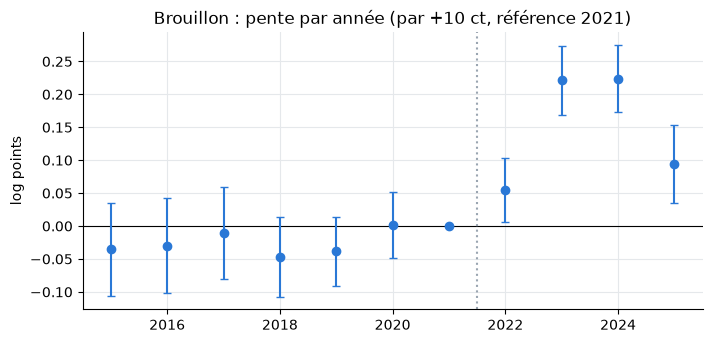

,pente,bas,haut
année,,,
2015,-0.035,-0.106,0.036
2016,-0.030,-0.101,0.042
2017,-0.011,-0.081,0.060
2018,-0.047,-0.107,0.014
2019,-0.038,-0.091,0.014
2020,0.002,-0.049,0.052
2021,0.000,0.000,0.000
2022,0.054,0.006,0.103
2023,0.222,0.169,0.274


In [36]:
# BROUILLON étape 1 : une pente par année, référence 2021, intervalles regroupés par gestionnaire
base = np.log1p(installs[installs.year == 2021].set_index("bfs").n_new)
pentes = []
for annee in range(2015, 2026):
    if annee == 2021:
        pentes.append((annee, 0.0, 0.0, 0.0))
        continue
    croissance = np.log1p(installs[installs.year == annee].set_index("bfs").n_new) - base
    croissance = croissance - croissance.groupby(communes.canton).transform("mean")
    ajustement = sm.OLS(croissance, sm.add_constant(x / 10)).fit(cov_type="cluster", cov_kwds={"groups": communes.operator})
    bas, haut = ajustement.conf_int().loc["shock23"]
    pentes.append((annee, ajustement.params["shock23"], bas, haut))

pentes = pd.DataFrame(pentes, columns=["année", "pente", "bas", "haut"]).set_index("année")
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.axhline(0, color="black", lw=.8); ax.axvline(2021.5, color=GRIS, ls=":")
ax.errorbar(pentes.index, pentes.pente, yerr=[pentes.pente - pentes.bas, pentes.haut - pentes.pente], fmt="o", color=BLEU, capsize=3)
ax.set(title="Brouillon : pente par année (par +10 ct, référence 2021)", ylabel="log points")
plt.show()
pentes.round(3)

**À lire** : avant 2021 les points doivent être proches de zéro (pas de tendance avant le choc). Le point 2022 dit s'il y a eu de l'anticipation. 2023 à 2025 montrent la taille de l'effet et s'il dure.

### Étape 2 : le modèle principal, un « double différence » (différence de différences)
**Quoi** : comparer l'évolution avant/après des communes à fort et à faible choc, dans le même canton et la même année.

**Pourquoi** : c'est la méthode standard quand un choc touche des groupes plus ou moins fort à un moment précis. Elle suppose que, sans le choc, les communes auraient suivi la même tendance (d'où l'étape 1).

**Avec quel modèle** : une régression de **Poisson** (PPML) plutôt que l'OLS sur log(1 + n). Poisson est fait pour les comptages avec des zéros, il n'a pas besoin du « +1 », et son coefficient se lit en pourcentage. On garde l'OLS à côté pour comparer.

**Effets fixes** : commune (ce qui est propre à chaque commune) et canton×année (tout ce qui change dans un canton une année donnée : subventions, règles, TVA…).

### Étape 3 : comparer des communes voisines
**Quoi** : des paires de communes **qui se touchent**, dans le même canton, mais servies par des gestionnaires différents.

**Pourquoi** : deux voisines partagent presque tout (climat, installateurs, médias locaux), sauf le gestionnaire et donc le tarif. C'est la comparaison la plus propre qu'on ait.

**Attention** : les effets de débordement (« spillovers »). Un installateur peut quitter la commune à faible choc pour celle à fort choc, ou les voisins peuvent s'imiter. Il faut mesurer ça aussi.

### Étape 4 : séparer le prix de détail et le tarif de reprise
**Quoi** : mettre X et la hausse du tarif de reprise (VESE) **ensemble** dans la même régression.

**Pourquoi** : c'est le principal « autre chose » de la section 5 (r = 0,79). Si le coefficient de X reste et celui du tarif de reprise tombe à zéro, la réaction suit surtout le prix évité. Avec une corrélation aussi forte, il reste peu de variation pour séparer les deux, il faudra le dire.

### Étape 5 : Z pour de vrai
**Quoi** : Z en **continu** (pas juste coupé à la médiane), en interaction avec le choc, avec des contrôles (taille de la commune, maisons individuelles, revenu).

**Pourquoi** : la différence de la slide 14 peut venir de la taille des communes ou du type de logement, et elle existait déjà en 2022. Si on teste plusieurs variables de ce type, il faut corriger pour les tests multiples (sinon on trouve des effets par hasard).

**Données** : chercher des données de propriétaires plus récentes que 2000 (relevé structurel de l'OFS).

### Étape 6 : vérifier que le résultat tient (robustesse)
- **D'autres façons de calculer l'incertitude** : regrouper par canton, bootstrap.
- **Inférence par permutation** : on mélange les chocs entre gestionnaires d'un même canton des centaines de fois. Si notre vrai coefficient est plus grand que presque tous les coefficients obtenus au hasard, ce n'est pas un coup de chance.
- **Effet de dose** : est-ce que l'effet vient surtout des grosses hausses (par exemple au-dessus de 6 ct) ?
- **Tailles d'installation** : est-ce que les petites installations de maisons réagissent comme les grandes ?

### Étape 7 : l'ampleur
**Quoi** : combien d'installations en plus le choc a causé, par rapport à un monde sans hausse.

**Pourquoi** : pour la discussion politique (le coût pour les ménages, ce que ça rapporte en électricité).

**Ce qu'on ne pourra pas dire** : une vraie élasticité de long terme. Ce choc était unique, énorme et en pleine crise.